##Загрузка изображения

In [1]:
import urllib.request

url = "https://i.pinimg.com/1200x/4b/12/2a/4b122a0b9ffe8f5d95a9181556f86f7d.jpg"
file_name = "picture.jpg"
urllib.request.urlretrieve(url, file_name)

('picture.jpg', <http.client.HTTPMessage at 0x7aeb63982990>)

(866, 750)


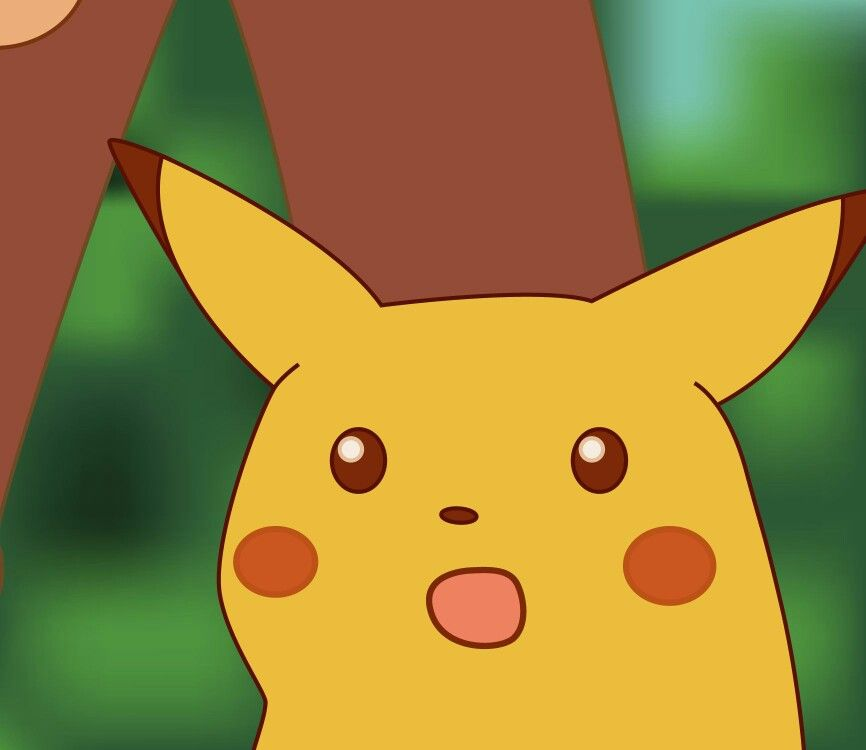

In [2]:
from PIL import Image

picture = Image.open(file_name).convert("RGB")
print(picture.size)
picture

In [3]:
import numpy as np

picture_array = np.array(picture)
height, width, _ = picture_array.shape
height, width

(750, 866)

In [4]:
red = picture_array[:, :, 0]
green = picture_array[:, :, 1]
blue = picture_array[:, :, 2]

red.shape

(750, 866)

##Разложение SVD

In [5]:
red_svd = np.linalg.svd(red, full_matrices=False)
green_svd = np.linalg.svd(green, full_matrices=False)
blue_svd = np.linalg.svd(blue, full_matrices=False)

red_svd.U.shape, red_svd.S.shape, red_svd.Vh.shape

((750, 750), (750,), (750, 866))

In [6]:
def approximate(U, S, Vh, rank):
    return (U[:, :rank] * S[:rank]) @ Vh[:rank, :]


red_new = approximate(red_svd.U, red_svd.S, red_svd.Vh, 1)
green_new = approximate(green_svd.U, green_svd.S, green_svd.Vh, 1)
blue_new = approximate(blue_svd.U, blue_svd.S, blue_svd.Vh, 1)

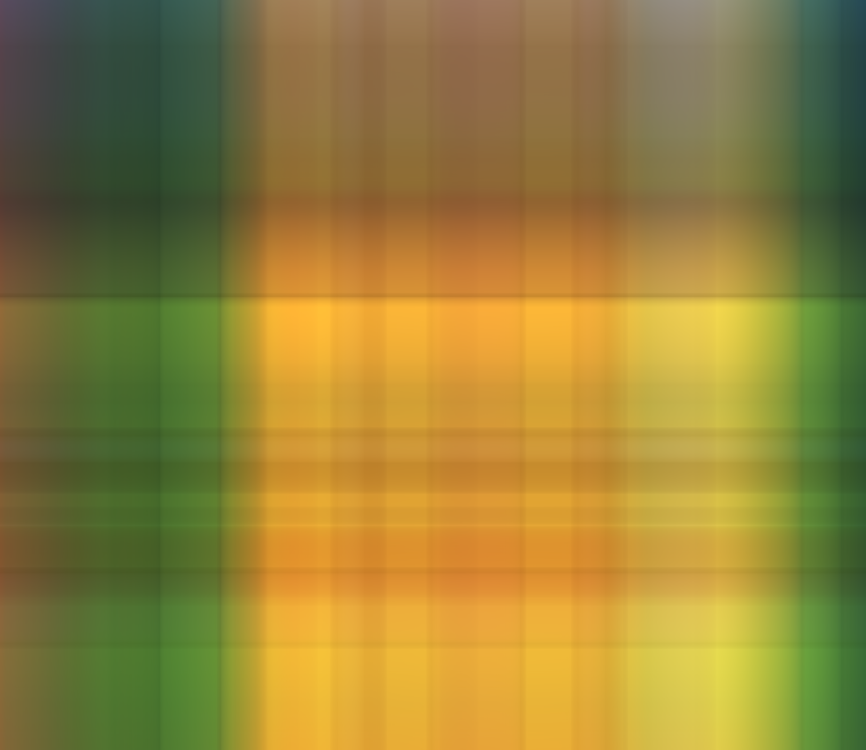

In [7]:
def combine_channels(red, green, blue):
    result = np.dstack([red, green, blue])
    return np.clip(result, 0, 255).astype(np.uint8)


new_picture = combine_channels(red_new, green_new, blue_new)
Image.fromarray(new_picture)

##Сравнение изображений и расчёт сжатия

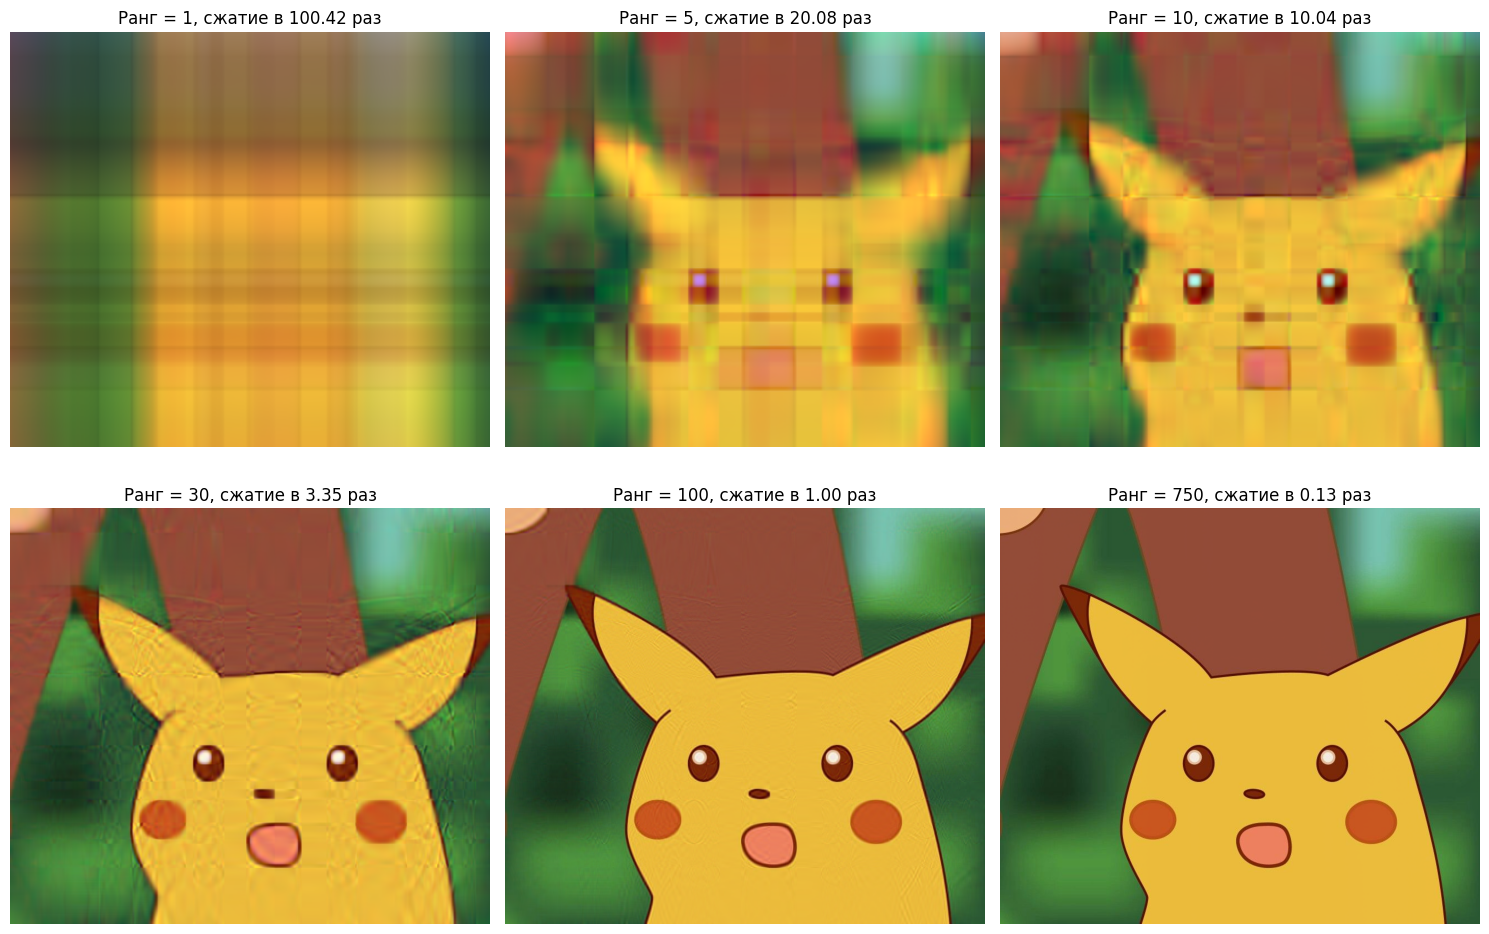

In [8]:
import matplotlib.pyplot as plt

ranks = [1, 5, 10, 30, 100, min(height, width)]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, rank in enumerate(ranks):
    red_new = approximate(red_svd.U, red_svd.S, red_svd.Vh, rank)
    green_new = approximate(green_svd.U, green_svd.S, green_svd.Vh, rank)
    blue_new = approximate(blue_svd.U, blue_svd.S, blue_svd.Vh, rank)

    new_picture = combine_channels(red_new, green_new, blue_new)

    original_size = height * width * 3
    compressed_size = 3 * rank * (height + width + 1) * 4
    ratio = original_size / compressed_size

    axes[i].imshow(new_picture)
    axes[i].set_title(f"Ранг = {rank}, сжатие в {ratio:.2f} раз")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Выводы

При маленьком ранге изображение получается размытым, потому что сохраняется мало деталей. При увеличении ранга картинка становится чётче. При максимальном ранге она практически совпадает с оригиналом.

Для сжатия в 10 раз ранг должен быть не больше значения, которое получается из формулы `height * width / (40 * (height + width + 1))`. При больших рангах сжатие становится меньше, а иногда хранение матриц занимает даже больше места, чем исходный массив пикселей.

На ровных светлых и тёмных участках изображение восстанавливается проще. Там, где много мелких деталей и резкие переходы цветов, погрешность заметнее.